In [ ]:
# import libraries
import soccerdata as sd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import matplotlib.image as mping
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

In [ ]:
#specifying the seasons to be included in the analysis
season = ["2016/2017","2017/2018", "2018/2019", "2019/2020", "2020/2021", "2021/2022", "2022/2023", "2023/2024", "2024/2025", "2025/2026"]

In [ ]:
# scraping shot events
understat = sd.Understat(seasons=season, leagues="ENG-Premier League")
shots = understat.read_shot_events()

[10/15/26 11:19:51] INFO     Saving cached data to C:\Users\elvin\soccerdata\data\Understat          ]8;id=8182057;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=8182058;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_common.py#250\250]8;;\

[2026-10-15 11:19:51] INFO     TLSLibrary:_load_library:397 - Successfully loaded TLS library: C:\Users\elvin\anaconda3\envs\myenv\Lib\site-packages\tls_requests\bin\tls-client-xgo-1.13.1-windows-amd64.dll


                    INFO     Successfully loaded TLS library:                                      ]8;id=8182065;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\tls_requests\models\libraries.py\libraries.py]8;;\:]8;id=8182066;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\tls_requests\models\libraries.py#397\397]8;;\
                             C:\Users\elvin\anaconda3\envs\myenv\Lib\site-packages\tls_requests\bi                 
                             n\tls-client-xgo-1.13.1-windows-amd64.dll                                             

In [ ]:
#scraping match schedule to match the shot events with the correct games
schedule = understat.read_schedule().reset_index()

In [ ]:
# filtering shot events to only include goals then merging with schedule to get the home and away teams
goals = shots.reset_index()
goals = goals[goals['result'].isin(["Goal", "Own Goal"])]
goals = goals.merge(schedule[['game_id','home_team', 'away_team']], on="game_id")

In [ ]:
# understat credits own goals to the team that conceded the goal, this is to make sure the goals are assigned to the correct team 
og = goals['result'] == 'Own Goal'
goals['scoring_team'] = np.where(~og, goals['team'], #if the goal is not an own goal, the scoring team is the team that scored the goal
             np.where(goals['team']== goals['home_team'], goals['away_team'], goals['home_team']))#else if the goal is an own goal, the scoring team is the team that conceded the goal


# filtering for the first goal in each game and creating a new column for the winner of the game
opener = (goals.sort_values(['game_id','minute',"shot_id"]).groupby('game_id').first()[["scoring_team",'minute']]
          .rename(columns={'scoring_team':'first_scorer','minute':"first_goal_min"}))

matches = schedule.merge(opener, on="game_id")
matches['winner'] = np.select([matches['home_goals']>matches['away_goals'], matches['home_goals']<matches['away_goals']],
          [matches['home_team'], matches['away_team']], default=None)


#filtering for games where the first goal scorer is not the winner of the game and the match is not a draw, i.e. comebacks
comebacks = matches[matches['winner'].notna() & (matches['first_scorer'] != matches['winner'])]

In [14]:
cb = comebacks[['season','date','home_team','away_team','home_goals','away_goals','first_scorer','winner','first_goal_min']].sort_values(['season','date'])

In [10]:
comebacks.groupby(['season','winner']).size().unstack(fill_value=0).sort_index()

winner,Arsenal,Aston Villa,Bournemouth,Brentford,Brighton,Burnley,Cardiff,Chelsea,Crystal Palace,Everton,...,Sheffield United,Southampton,Stoke,Sunderland,Swansea,Tottenham,Watford,West Bromwich Albion,West Ham,Wolverhampton Wanderers
season,,,,,,,,,,,,,,,,,,,,,
1617,2,0,2,0,0,0,0,4,3,3,...,0,3,0,1,2,4,2,3,2,0
1718,3,0,5,0,0,2,0,2,4,3,...,0,1,2,0,2,3,2,0,1,0
1819,2,0,1,0,1,3,3,2,1,0,...,0,1,0,0,0,3,2,0,3,3
1920,4,2,1,0,1,1,0,2,2,1,...,2,3,0,0,0,4,2,0,1,4
2021,3,2,0,0,1,1,0,3,2,1,...,1,3,0,0,0,4,0,1,4,4
2122,1,1,0,4,2,1,0,2,1,4,...,0,1,0,0,0,4,1,0,4,1
2223,5,1,4,2,2,0,0,2,7,1,...,0,3,0,0,0,4,0,0,2,2
2324,2,4,3,1,3,0,0,3,2,0,...,0,0,0,0,0,7,0,0,5,3
2425,3,4,3,5,5,0,0,4,2,2,...,0,0,0,0,0,3,0,0,0,2


In [11]:
comebacks.groupby('season')['winner'].count()

season
1617    44
1718    43
1819    41
1920    45
2021    56
2122    43
2223    55
2324    54
2425    59
2526    46
Name: winner, dtype: int64

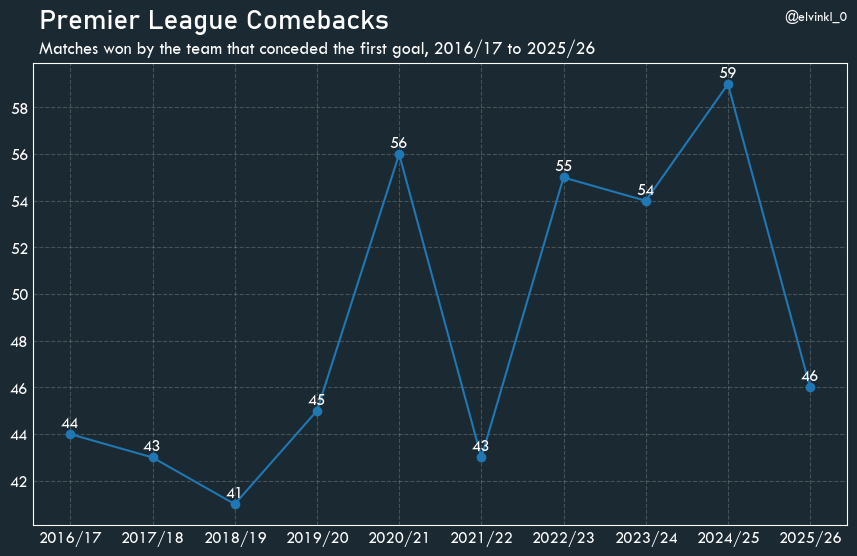

In [ ]:
fig, ax = plt.subplots(figsize=(10.5,6)) #size of the figure
fig.patch.set_facecolor('#1b2932') #background color
ax.set_facecolor('#1b2932') #plot area background color

cb_per_season = comebacks.groupby('season')['winner'].count().reset_index() 
cb_per_season['season'] = '20' + cb_per_season['season'].str[:2] + '/' + cb_per_season['season'].str[2:]
ax.plot(cb_per_season['season'], cb_per_season['winner'], marker='o', color='#1f77b4') #plots line chart with a blue line and circular markers

# Annotates the data points for each point in the line chart
for season, count in zip(cb_per_season['season'], cb_per_season['winner']):
    ax.annotate(str(count), xy=(season, count), xytext=(0, 5), textcoords='offset points', ha='center', color='white', fontfamily='Tw Cen MT', fontsize=12)

fig.text(0.13, 0.97, "Premier League Comebacks", color='white', fontfamily='Bahnschrift', fontsize=20, ha='left', va='top')
fig.text(0.13, 0.92, "Matches won by the team that conceded the first goal, 2016/17 to 2025/26", color='white', fontfamily='Tw Cen MT', fontsize=13, ha='left', va='top')
fig.text(0.9, 0.97, "@elvinkl_0", color='white', fontfamily='Tw Cen MT', fontsize=10, ha='right', va='top')

ax.tick_params(axis='y', colors='white', length=0, labelsize=12, labelfontfamily='Tw Cen MT')
ax.tick_params(axis='x', colors='white', length=0, labelsize=12, labelfontfamily='Tw Cen MT')

ax.yaxis.set_major_locator(MultipleLocator(2)) #changing the y-axis ticks to be in increments of 2

for spine in ax.spines.values():
    spine.set_color('white')
ax.grid(axis='y',linestyle='--',alpha=0.3)
ax.grid(axis='x',linestyle='--',alpha=0.3)
plt.show()


## Comebacks for each Prem team

In [ ]:
#creating a df with the number of comebacks per team per season
team_cb = cb.groupby(['season','winner']).size().unstack(fill_value=0).sort_index()

# a filter to check which teams were in the league. This is to make it so that if a team were in the league and had 0 comebacks that season, 0 would be plotted but if a team was not in the league that season, it would be left blank. This is to avoid confusion as to why a team has 0 comebacks in a season when they were not even in the league that season.
in_league = (pd.concat([schedule[['season','home_team']].rename(columns={'home_team':'team'}),
                       schedule[['season','away_team']].rename(columns={'away_team':'team'})]).drop_duplicates()
                       .assign(played=True)
                       .pivot(index='season',columns='team',values='played')
                       .reindex(index=team_cb.index, columns=team_cb.columns)
                       .fillna(False)
                       .astype(bool))

team_cb = team_cb.where(in_league)
team_cb.index = team_cb.index.str[:2]+"/"+team_cb.index.str[2:] #changing the index to be in the format of 20xx/xx instead of xx/xx
team_cb = team_cb.loc[:,team_cb.isnull().sum()<=3] #filtering out teams that were not in the league for more than 3 seasons, this is to avoid cluttering the plot with too many teams
teams = team_cb.columns



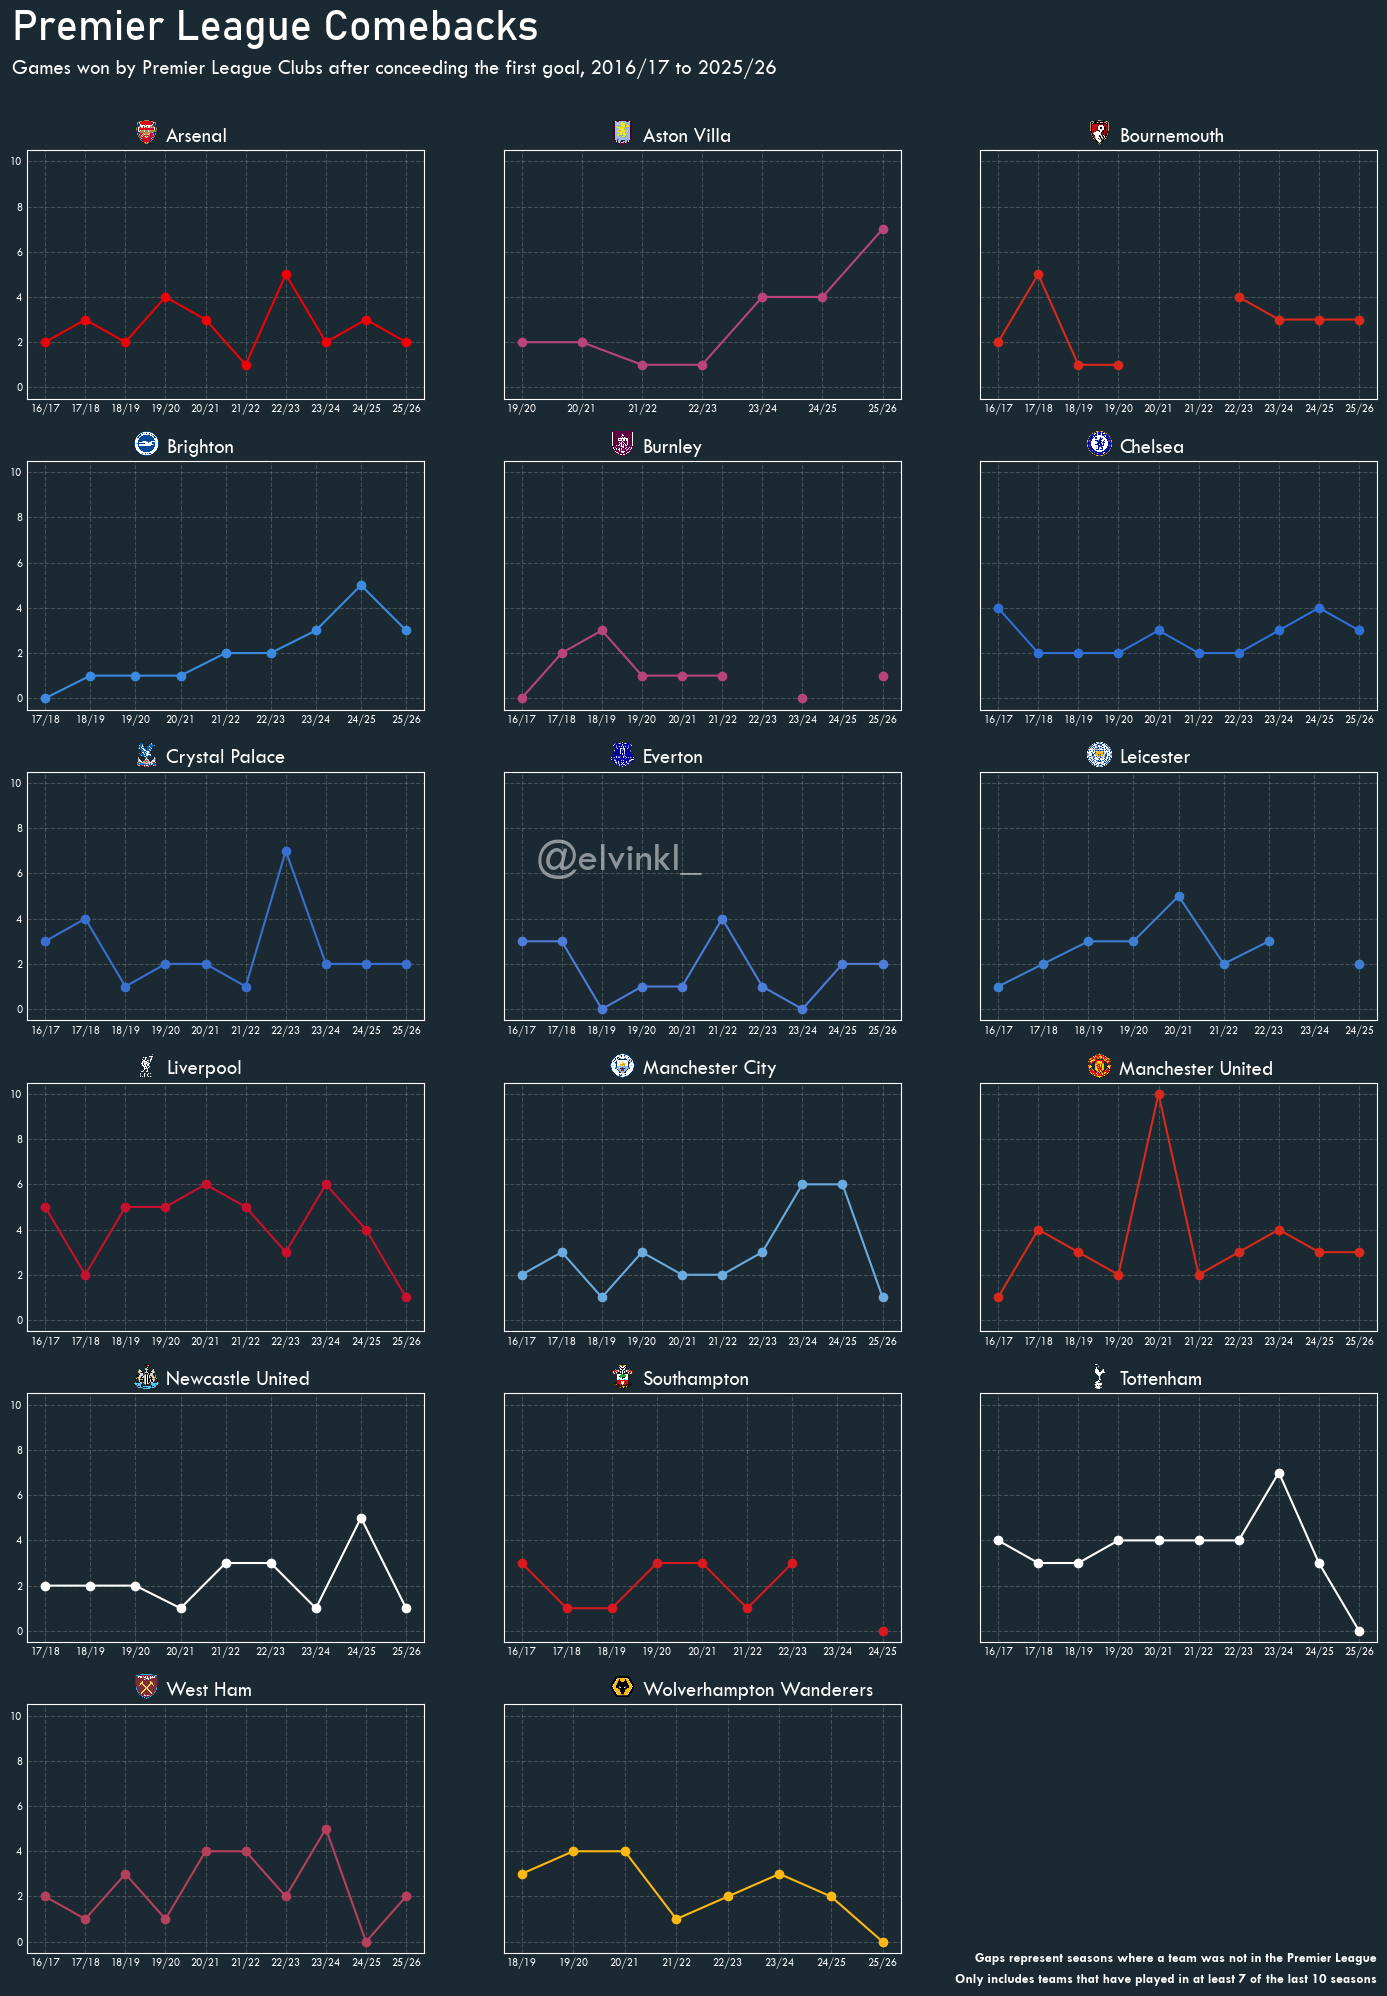

In [171]:
ncols = 3
nrows = (len(teams) + ncols - 1) // ncols

#club colors for each premier league team.
club_colors = {
    'Arsenal': '#EF0107', 'Aston Villa': '#B8457A', 'Bournemouth': '#DA291C', 'Brentford': '#E30613',
    'Brighton': '#3C8BE0', 'Burnley': '#B8457A', 'Cardiff': '#0070B5', 'Chelsea': '#2F6FD6',
    'Crystal Palace': '#3A6FD0', 'Everton': '#4F7BD9', 'Fulham': '#FFFFFF', 'Huddersfield': '#0E63AD',
    'Hull': '#F5A12D', 'Ipswich': '#3A64A3', 'Leeds': '#FFCD00', 'Leicester': '#3D7FD0',
    'Liverpool': '#C8102E', 'Luton': '#F78F1E', 'Manchester City': '#6CABDD', 'Manchester United': '#DA291C',
    'Middlesbrough': '#E21A23', 'Newcastle United': '#FFFFFF', 'Norwich': '#00A650', 'Nottingham Forest': '#DD0000',
    'Sheffield United': '#EE2737', 'Southampton': '#D71920', 'Stoke': '#E03A3E', 'Sunderland': '#EB172B',
    'Swansea': '#FFFFFF', 'Tottenham': '#FFFFFF', 'Watford': '#FBEE23', 'West Bromwich Albion': '#122F67',
    'West Ham': '#B5405E', 'Wolverhampton Wanderers': '#FDB913'
}

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5*nrows), sharey=True, gridspec_kw={'hspace': 0.25})
#fig.suptitle('How often does your team come back to win?', color='white', fontfamily='Bahnschrift', fontsize=20, ha='left', va='top')

axes = axes.flatten()
fig.patch.set_facecolor('#1b2932')

for i, team in enumerate(teams):
    ax = axes[i]
    ax.set_facecolor('#1b2932')
    ax.plot(team_cb.index, team_cb[team], marker='o', color=club_colors.get(team))
    
    ax.set_title(team, loc='left',x=0.35,color='white', fontfamily='Tw Cen MT', fontsize=15)
    ax.tick_params(axis='both', colors='white', length=0, labelsize=8, labelfontfamily='Tw Cen MT')
    ax.grid(linestyle='--',alpha=0.3)

    for spine in axes[i].spines.values():
            spine.set_color('white')


    # putting club badges next to team names        
    badge_path = Path('badges')/f'{team}.png'
    img = mping.imread(badge_path)
    zoom = 18/max(img.shape[:2])
    imagebox = OffsetImage(img, zoom=zoom)

    ab = AnnotationBbox(imagebox, (0.30, 1.07), frameon=False, xycoords='axes fraction')
    axes[i].add_artist(ab)

for ax in axes[len(teams):]:
    ax.set_visible(False)


fig_h = 3.5*nrows
header = 1.5

fig.subplots_adjust(top = 1 - header/fig_h, bottom=0.07, left=0.05, right=0.95)

fig.text(0.04, 1-0.1/fig_h, "Premier League Comebacks", color='white', fontfamily='Bahnschrift', fontsize=30, ha='left', va='top')
fig.text(0.04, 1-0.58/fig_h, "Games won by Premier League Clubs after conceeding the first goal, 2016/17 to 2025/26", color='white', fontfamily='Tw Cen MT', fontsize=15, ha='left', va='top')
fig.text(0.5, 0.6, "@elvinkl_", color='white', fontfamily='Tw Cen MT', fontsize=30, ha='right', va='top',alpha=0.5)
fig.text(0.95,0.06, "Only includes teams that have played in at least 7 of the last 10 seasons", color='white', fontfamily='Tw Cen MT', fontsize=10, ha='right', va='top', weight='bold')
fig.text(0.95,0.07, "Gaps represent seasons where a team was not in the Premier League", color='white', fontfamily='Tw Cen MT', fontsize=10, ha='right', va='top', weight='bold')

#plt.tight_layout(rect=[0, 0, 1, 0.86], h_pad=2)
plt.show()